<a href="https://colab.research.google.com/github/devKomori/cst383_final_project/blob/lazbranch/final_project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Machine Learning as an Aid Against Phishing and Fraud
---
## Authors:
Alan Becker,
Alexander Zambie,
Brennan Slate,
and Lazaro Martinez Jimenez


# Introduction

A phishing email is a fraudulent message from a cybercriminal who impersonates a trusted source to trick you into revealing sensitive information, such as passwords, credit card numbers, or bank details. In this report predictions will be made to distiguish if an email is phishing/fraudulent, or a real email.


## Dataset Choice
This project is using the [Phishing Email Dataset](https://www.kaggle.com/datasets/naserabdullahalam/phishing-email-dataset) from Kaggle. This dataset contains approximately 82,500 emails, with 42,891 labeled as phishing and 39,595 as legitimate. The emails are sourced from Enron, Ling, CEAS, Nazario, SpamAssassin, and Nigerian Fraud emails. For this project, we will focus on the CEAS subset, as it provides more relevant features and is less dated.


## Prediction Goal and Features
The goal of this project is to compare different machine learning models that can distinguish between phishing and legitimate emails based on their content.


We plan to use the columns `subject`, `body`, `sender`, and `urls` to predict the `label` column, which indicates whether an email is phishing or legitimate.









In [ ]:
# packages
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import rcParams
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import roc_curve, auc
from sklearn.metrics import cohen_kappa_score
from sklearn.linear_model import LogisticRegression

## Read Data

In [ ]:
df = pd.read_csv('data/CEAS_08.csv')

# Data Exploration and Cleaning

Looking at the data, there are 2 columns with missing values. 462 instances in the "receiver" column, and 28 in the "subject" column. Majority of the types are objects, with labesl and url's being int64.



In [ ]:
na_per_col = df.isna().sum().sort_values(ascending=False)
print(na_per_col)
print(df.info())

receiver    462
subject      28
sender        0
date          0
body          0
label         0
urls          0
dtype: int64
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 39154 entries, 0 to 39153
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   sender    39154 non-null  object
 1   receiver  38692 non-null  object
 2   date      39154 non-null  object
 3   subject   39126 non-null  object
 4   body      39154 non-null  object
 5   label     39154 non-null  int64 
 6   urls      39154 non-null  int64 
dtypes: int64(2), object(5)
memory usage: 2.1+ MB
None


## Data Preprocessing


Preparing the data for modeling by dropping unnecessary columns and handling missing values. Receiver and date will be dropped, as they do not have much impact on determining if an email is phishing or legitimate. Also filled the NA values of subject with ''. Also the Object types of sender, receiver, subject, and url's were changed to strings for future use.

In [ ]:
df = df.drop(["receiver", "date"], axis=1)
df = df.fillna('')
df["urls"] = df["urls"].astype("string").fillna("").str.strip()
df["sender"] = df["sender"].astype("string").fillna("").str.strip()
df["subject"] = df["subject"].astype("string").fillna("").str.strip()


## Data Exploration and Visualization


In [ ]:
df.info()
df.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 39154 entries, 0 to 39153
Data columns (total 5 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   sender   39154 non-null  string
 1   subject  39154 non-null  string
 2   body     39154 non-null  object
 3   label    39154 non-null  int64 
 4   urls     39154 non-null  string
dtypes: int64(1), object(1), string(3)
memory usage: 1.5+ MB


,sender,subject,body,label,urls
0,Young Esposito <Young@iworld.de>,Never agree to be a loser,"Buck up, your troubles caused by small dimensi...",1,1
1,Mok <ipline's1983@icable.ph>,Befriend Jenna Jameson,\nUpgrade your sex and pleasures with these te...,1,1
2,Daily Top 10 <Karmandeep-opengevl@universalnet...,CNN.com Daily Top 10,>+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+...,1,1
3,Michael Parker <ivqrnai@pobox.com>,Re: svn commit: r619753 - in /spamassassin/tru...,Would anyone object to removing .so from this ...,0,1
4,Gretchen Suggs <externalsep1@loanofficertool.com>,SpecialPricesPharmMoreinfo,\nWelcomeFastShippingCustomerSupport\nhttp://7...,1,1


# Count Plot of Features

Although there are imbalances in the distribution of some of these features, they capture meaningful behavioral differences between legitimate and phishing emails, so these features are kept for modeling.

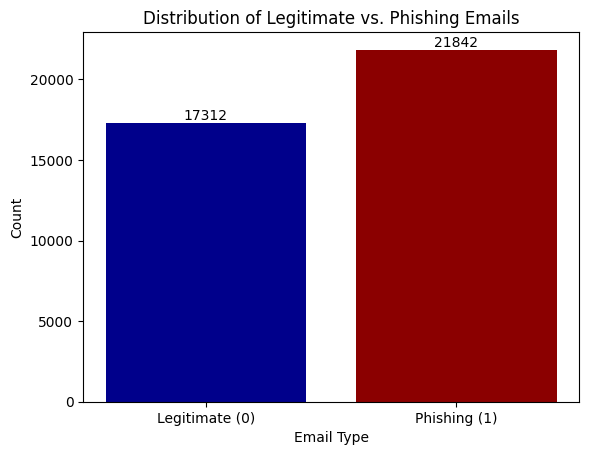

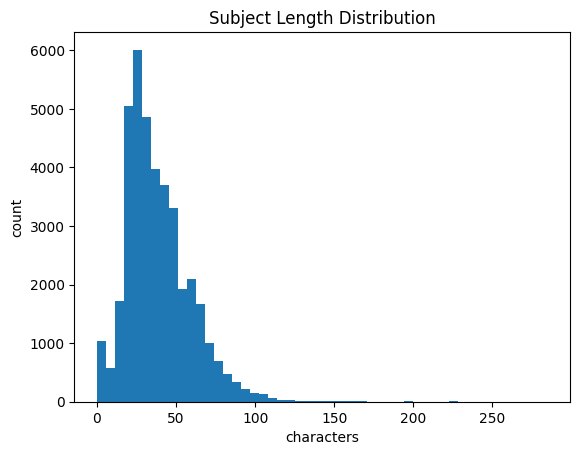

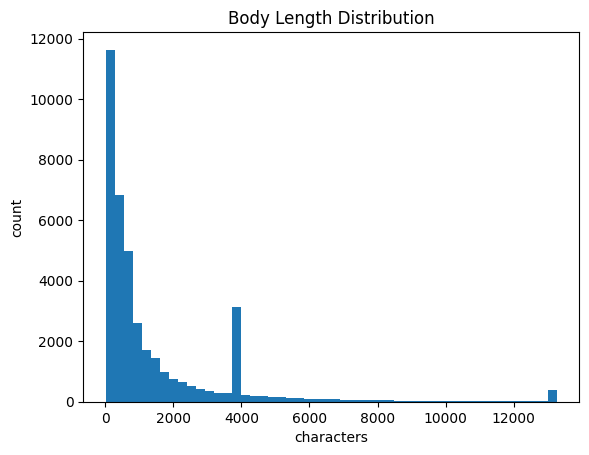

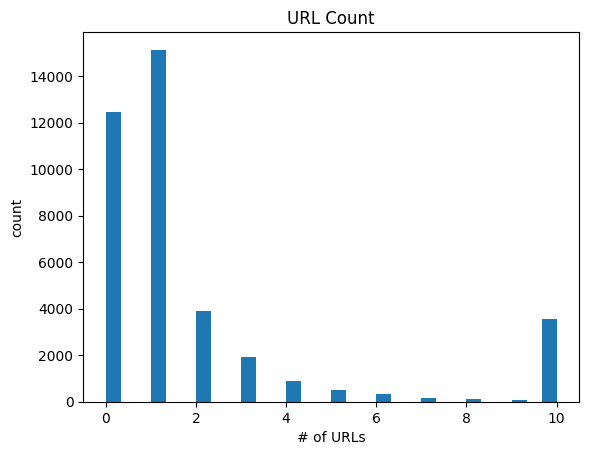

In [ ]:
url_pattern = r"(https?://|www\.)\S+"

df["n_urls"] = (
    df["urls"].str.count(url_pattern) +
    df["subject"].str.count(url_pattern) +
    df["body"].str.count(url_pattern)
)

df["subject_len"] = df["subject"].str.len()
df["body_len"] = df["body"].str.len()

# Legit vs Phishing Count
count = df['label'].value_counts()
bars = plt.bar(count.index, count.values, color=['darkred', 'darkblue'])
plt.title('Distribution of Legitimate vs. Phishing Emails')
plt.xlabel('Email Type')
plt.ylabel('Count')
plt.xticks([0, 1], ['Legitimate (0)', 'Phishing (1)'])
plt.bar_label(bars, fmt='%d', fontsize=10)
plt.show()

# Subject length
plt.figure()
df["subject_len"].plot(kind="hist", bins=50)
plt.title("Subject Length Distribution")
plt.xlabel("characters")
plt.ylabel("count")
plt.show()


#Body length
plt.figure()
df["body_len"].clip(upper=df["body_len"].quantile(0.99)).plot(kind="hist", bins=50)
plt.title("Body Length Distribution")
plt.xlabel("characters")
plt.ylabel("count")
plt.show()

# URL's per email count
plt.figure()
df["n_urls"].clip(upper=10).plot(kind="hist", bins=30)
plt.title("URL Count")
plt.xlabel("# of URLs")
plt.ylabel("count")
plt.show()



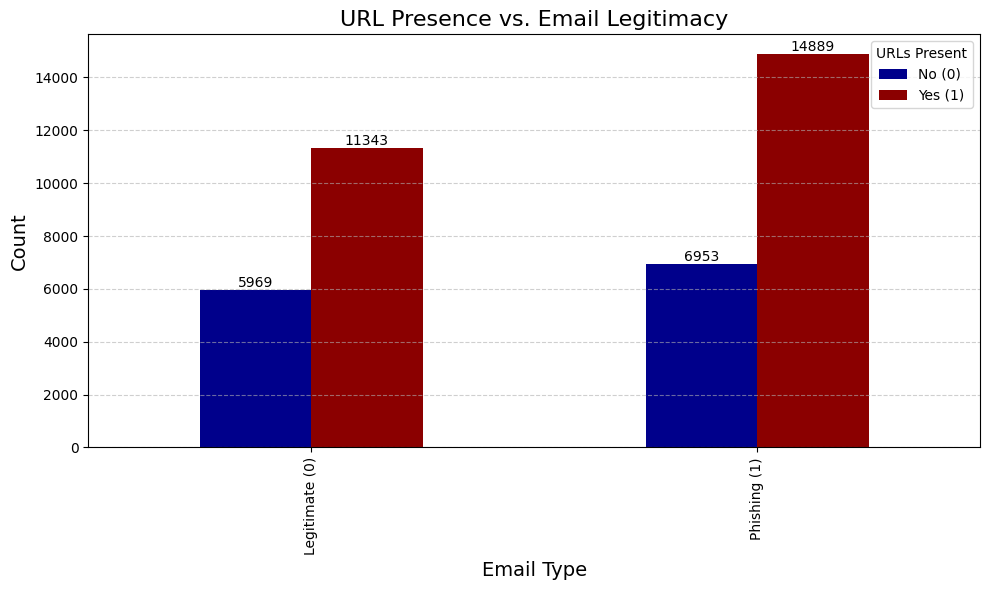

In [ ]:
plot_data = pd.crosstab(df['label'], df['urls'])
fig, ax = plt.subplots(figsize=(10, 6))
plot_data.plot(kind='bar', ax=ax, color=['darkblue', 'darkred'])
ax.set_title('URL Presence vs. Email Legitimacy', fontsize=16)
ax.set_xlabel('Email Type', fontsize=14)
ax.set_ylabel('Count', fontsize=14)
ax.set_xticklabels(['Legitimate (0)', 'Phishing (1)'])
ax.legend(title='URLs Present', labels=['No (0)', 'Yes (1)'], loc='upper right')
for container in ax.containers:
    ax.bar_label(container, fmt='%d', fontsize=10)
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

## Machine Learning


In [ ]:
df['predictor'] = (df['subject'] + ' ' + df['body'] + ' ' + df['sender']) + ' ' + df['urls'].astype(str)
vectorizer = TfidfVectorizer()
X = vectorizer.fit_transform(df['predictor'])
y = df['label'].values
# Splitting the data into training and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

## Logistic Regression Approach


In [ ]:
model = LogisticRegression()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:,1]
train = model.score(X_train, y_train)
test = model.score(X_test, y_test)

print("Train Accuracy: {:2f}%".format(train*100))
print("Test Accuracy: {:2f}%".format(test*100))

Train Accuracy: 99.556237%
Test Accuracy: 99.246584%


In [ ]:
fpr, tpr, thresholds = roc_curve(y_test, y_prob)
roc_auc = auc(fpr, tpr)

kappa = cohen_kappa_score(y_test, y_pred)
print("Kappa Coefficient:", round(kappa, 2))

Kappa Coefficient: 0.98


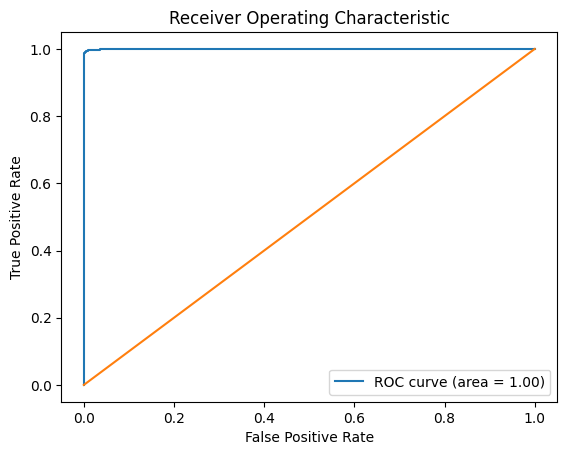

In [ ]:
plt.figure()
plt.plot(fpr, tpr, label='ROC curve (area = {:.2f})'.format(roc_auc))
plt.plot([0, 1], [0, 1])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic')
plt.legend(loc="lower right")
plt.show()